# EMNIST Letters CNN and ResNet Extension

In [1]:
# Restricts GPU usage
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

c:\Users\ephra\anaconda3\envs\gpu_env\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Load data
data = pd.read_csv("emnist-letters.csv")

In [4]:
# Separate labels and pixel data using pandas iloc
labels = data.iloc[:, 0].values
pixels = data.iloc[:, 1:].values

# Identify unique labels and counts
unique_labels, counts = np.unique(labels, return_counts=True)
print(f"Unique Labels: {unique_labels}")
print(f"Number of samples: {len(labels)}")

Unique Labels: [-2 -1  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26]
Number of samples: 99039


In [5]:
print(f"Number of values in pixel[1]: {pixels[1].size}")
print(pixels[1])

Number of values in pixel[1]: 784
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   4  21  50 125 114  39
  37  32   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   3  77 140 203 233 250 254 253 250 250 243 127  10   0   0   0   0
   0   0   0   0   0   0   0   0   0   0  20 170 241 204 140 127 127 127
 127 141 220 254 253 208 115   8   0   0   0   0   0   0   0   0   0   0
   0   1  95 248 195  36   9   4   4   4   4  11  79 208 253 254 243  96
  34   1   0   0   0   0   0   0   0   0   1  47 243 195  12   0   0   0
   0   0   0   0 

Issues spotted:


Extra labels -1 and -2 (Not in alphabets)

Data is already flattened (784 pixels = 28*28) so we reshape back to image



-----------------
Visualising


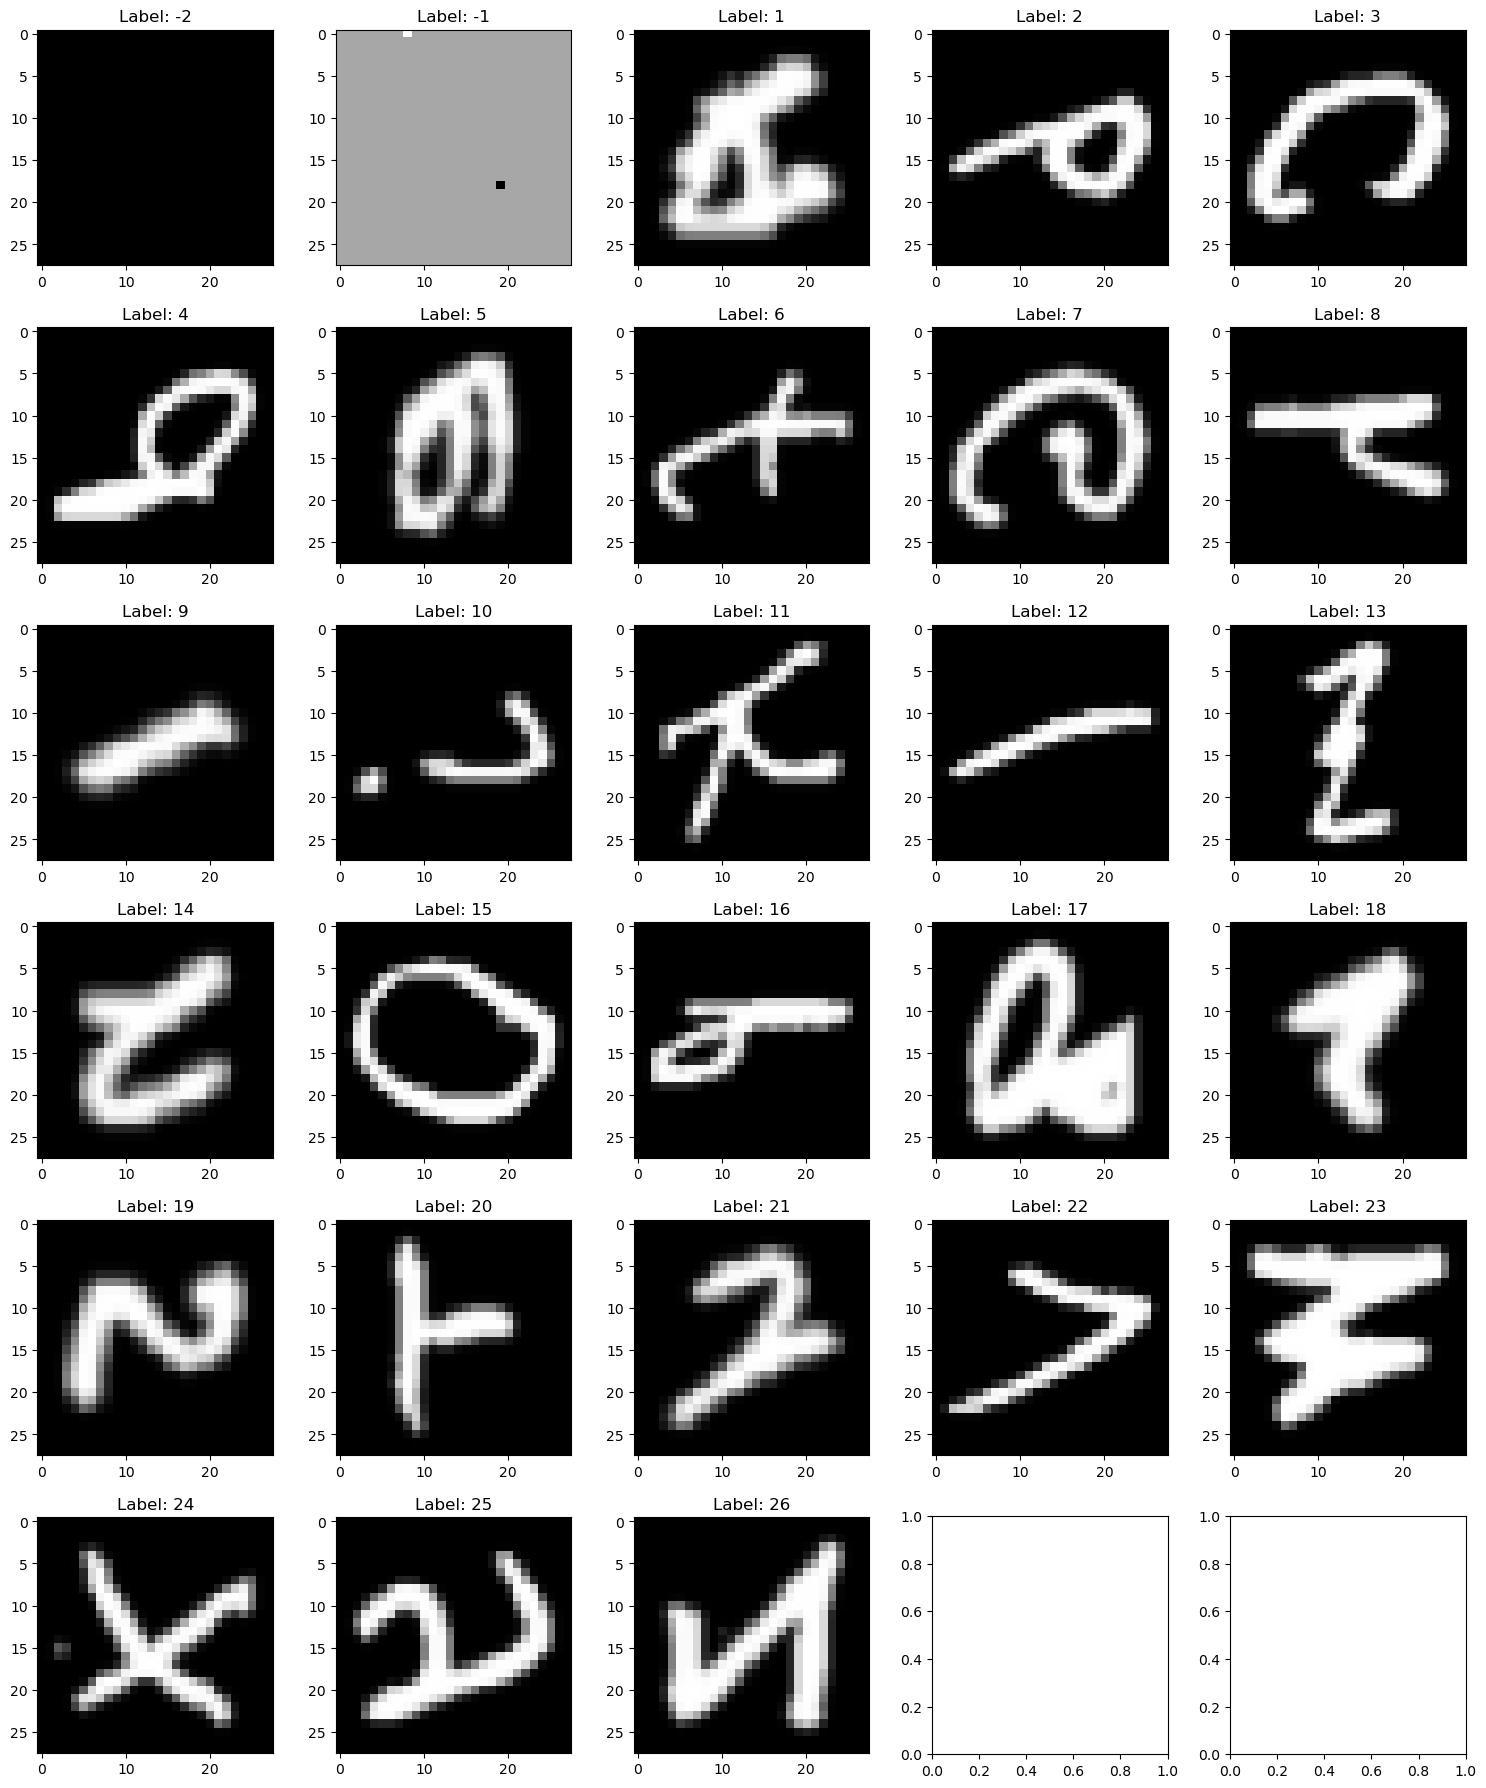

In [6]:
unique_labels = sorted(data.iloc[:, 0].unique())
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
axes = axes.flatten()

for i, label in enumerate(unique_labels):
    img = data[data.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {label}")


plt.tight_layout()
plt.show()

Issues:



1) The orientation of the letters are disoriented.
  
   - Solution: need to flip across x axis first, then rotate it 90 degrees clockwise

2) Label -2 and -1 seem to be plain data





In [7]:
import numpy as np

# Loop through and fix orientation in-place
for i in range(len(pixels)):
    # Reshape to 28x28
    img = pixels[i].reshape(28, 28)

    # Fix orientation
    img_flipped = np.flip(img, axis=-1)
    img_fixed = np.rot90(img_flipped)

    # Flatten back into the same array
    pixels[i] = img_fixed.flatten()

# Sync back to the main dataframe
data.iloc[:, 1:] = pixels



test if orientation is fixed

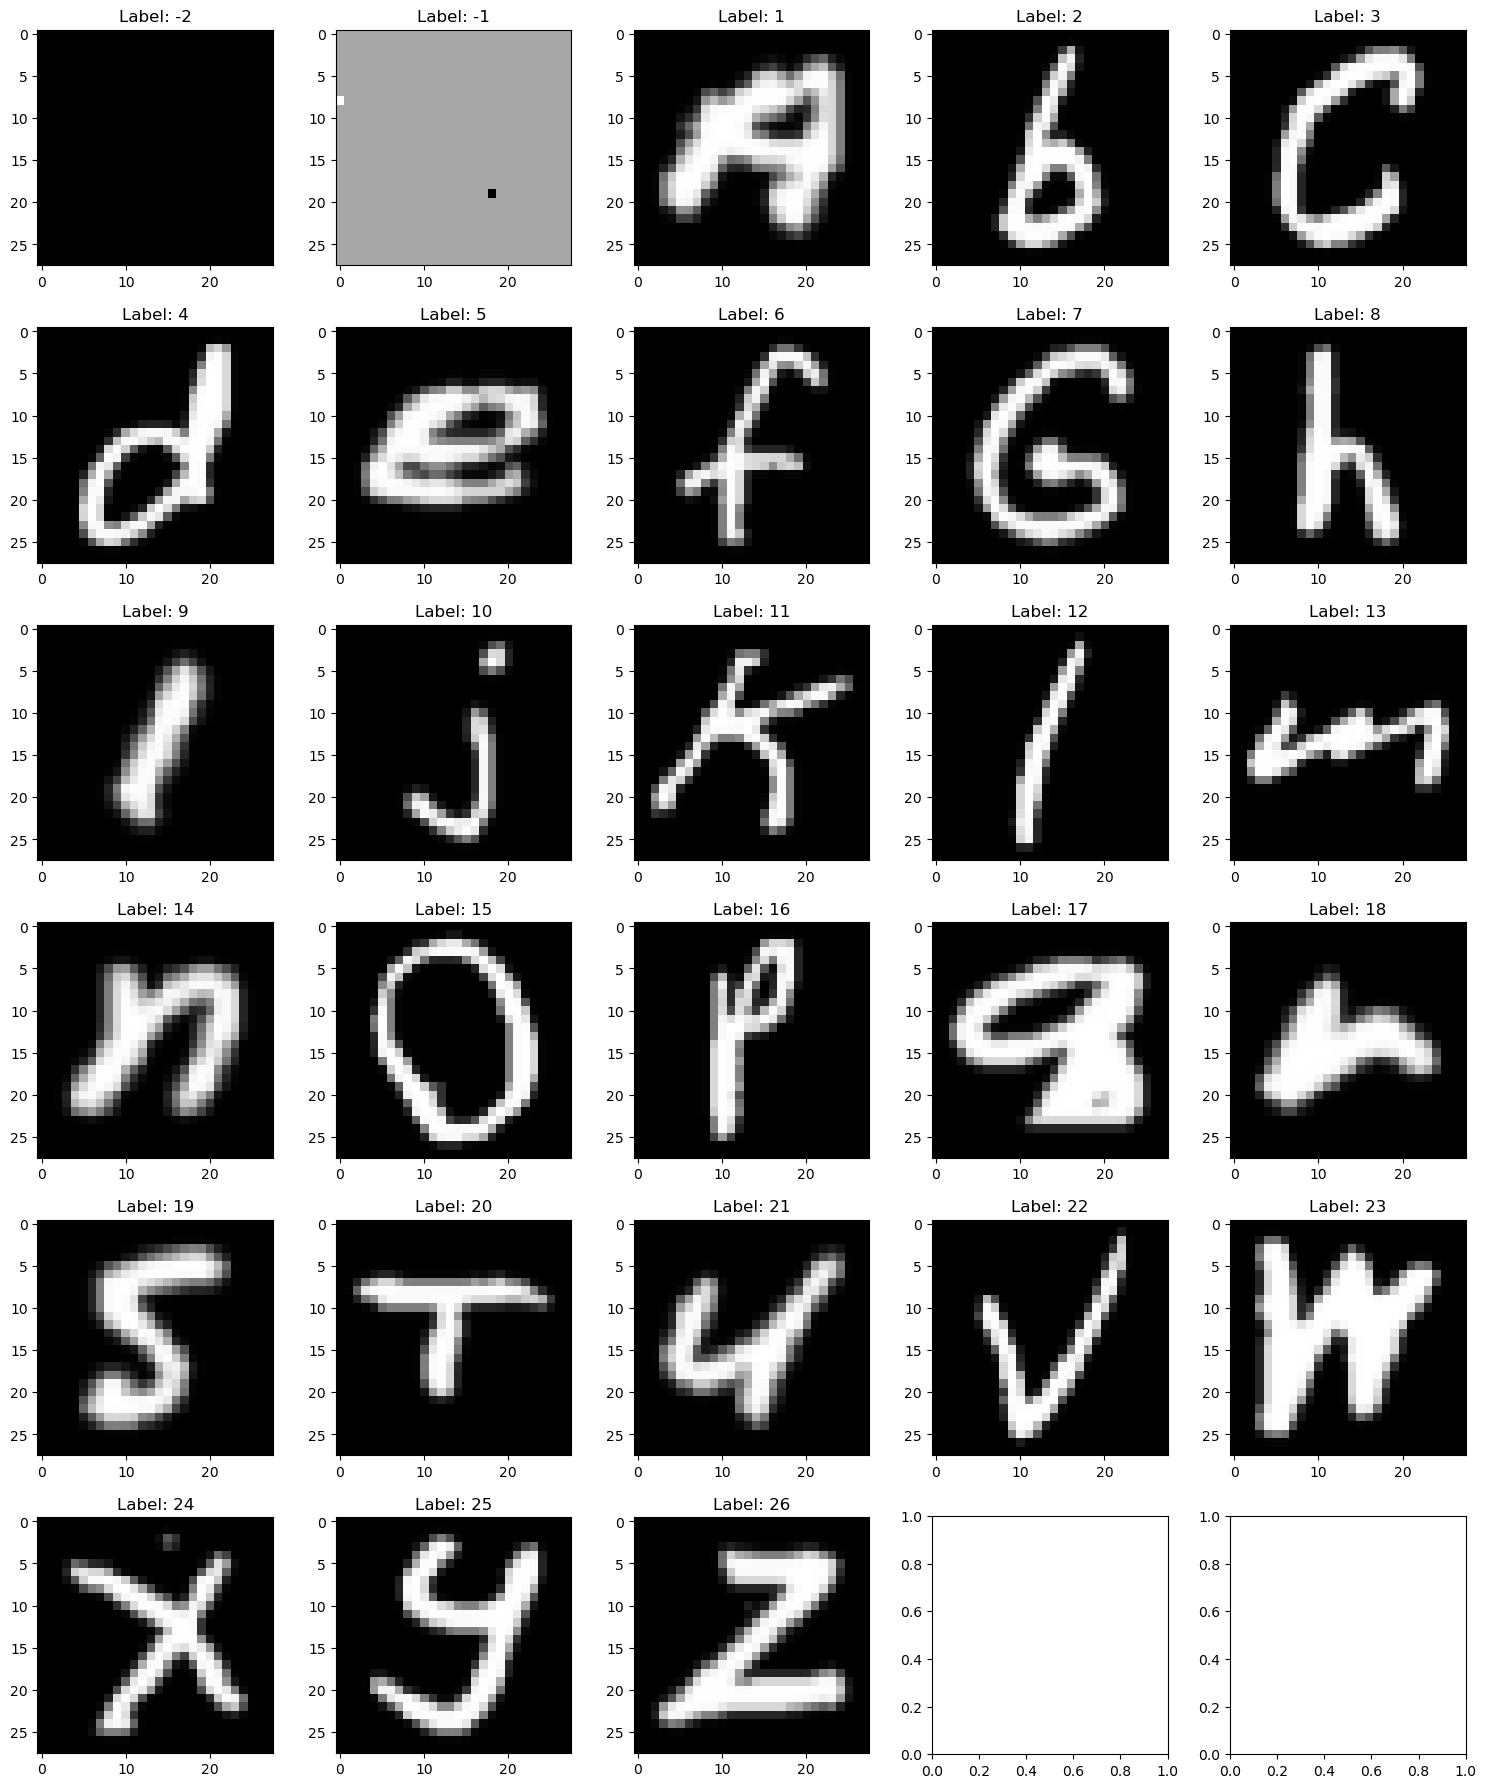

In [8]:
unique_labels = sorted(data.iloc[:, 0].unique())
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
axes = axes.flatten()

for i, label in enumerate(unique_labels):
    img = data[data.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {label}")


plt.tight_layout()
plt.show()

In [9]:
print(f"Total samples remaining: {len(data)}")

Total samples remaining: 99039


Label -1 and -2 Look like unnecessary data. We can drop these 2 labels.

In [10]:
data = data[np.isin(labels, [-1, -2]) == False]
labels = data.iloc[:, 0].values - 1  # remap original labels 1-26 to 0-25
pixels = data.iloc[:, 1:].values
data.iloc[:, 0] = labels

print(f"Remaining Unique Labels: {np.unique(labels)}")
print(f"Total samples remaining: {len(data)}")

Remaining Unique Labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]
Total samples remaining: 88799


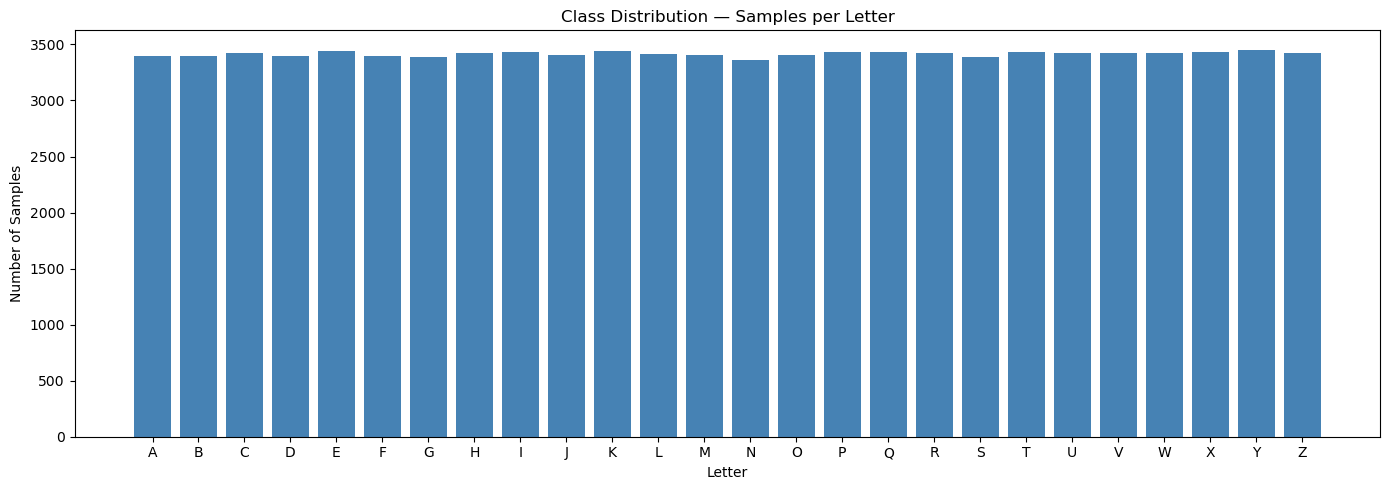

Min samples in a class: 3365
Max samples in a class: 3453


In [11]:
# Class distribution bar chart
unique_labels, counts = np.unique(labels, return_counts=True)
label_names = [chr(i + 65) for i in unique_labels]  # 1=A, 2=B ... 26=Z

plt.figure(figsize=(14, 5))
plt.bar(label_names, counts, color='steelblue')
plt.title('Class Distribution — Samples per Letter')
plt.xlabel('Letter')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

print(f"Min samples in a class: {counts.min()}")
print(f"Max samples in a class: {counts.max()}")

Check Every Set of each alphabet

EDA FINISHED

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.utils import to_categorical

In [13]:
from sklearn.model_selection import train_test_split

# Splitting the data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    pixels,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 71039
Testing samples: 17760


In [14]:
# fix random seed for reproducibility
seed = 1
np.random.seed(seed)

In [15]:
# reshape to be [samples][height][width][channel]
# default in TF is N H W C
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32')
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1).astype('float32')
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255
# one hot encode outputs
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
num_classes = y_test.shape[1]
# build the model
# create model
model = Sequential()
model.add(Conv2D(32, (5, 5), input_shape=(28, 28, 1), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
# Compile model
model.compile(loss='categorical_crossentropy',
 optimizer='adam', metrics=['accuracy'])
# Fit the model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
 epochs=10, batch_size=200, verbose=1)
# Final evaluation of the model
scores = model.evaluate(X_test, y_test, verbose=0)
print("CNN Error: %.2f%%" % (100-scores[1]*100))

Epoch 1/10
356/356 [==============================] - 16s 9ms/step - loss: 0.8171 - accuracy: 0.7587 - val_loss: 0.4622 - val_accuracy: 0.8603
Epoch 2/10
356/356 [==============================] - 2s 6ms/step - loss: 0.3818 - accuracy: 0.8795 - val_loss: 0.3398 - val_accuracy: 0.8945
Epoch 3/10
356/356 [==============================] - 2s 6ms/step - loss: 0.3030 - accuracy: 0.9024 - val_loss: 0.3239 - val_accuracy: 0.8975
Epoch 4/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2654 - accuracy: 0.9121 - val_loss: 0.2745 - val_accuracy: 0.9144
Epoch 5/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2328 - accuracy: 0.9225 - val_loss: 0.2706 - val_accuracy: 0.9153
Epoch 6/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2125 - accuracy: 0.9275 - val_loss: 0.2504 - val_accuracy: 0.9211
Epoch 7/10
356/356 [==============================] - 2s 6ms/step - loss: 0.1926 - accuracy: 0.9337 - val_loss: 0.2683 - val_accuracy: 0.9166
Epoch

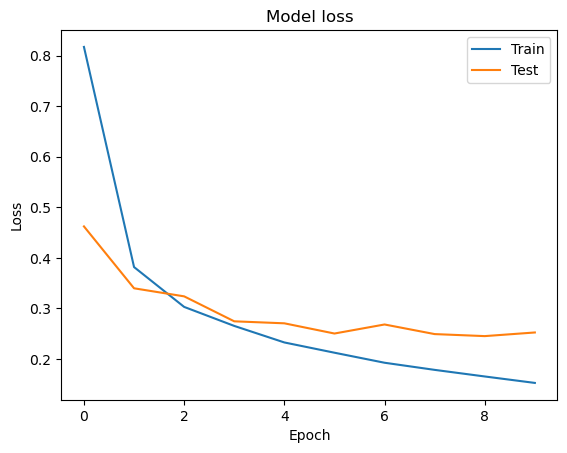

In [16]:
def plot_loss(loss,val_loss):
  plt.figure()
  plt.plot(loss)
  plt.plot(val_loss)
  plt.title('Model loss')
  plt.ylabel('Loss')
  plt.xlabel('Epoch')
  plt.legend(['Train', 'Test'], loc='upper right')
  plt.show()


plot_loss(history.history['loss'], history.history['val_loss'])

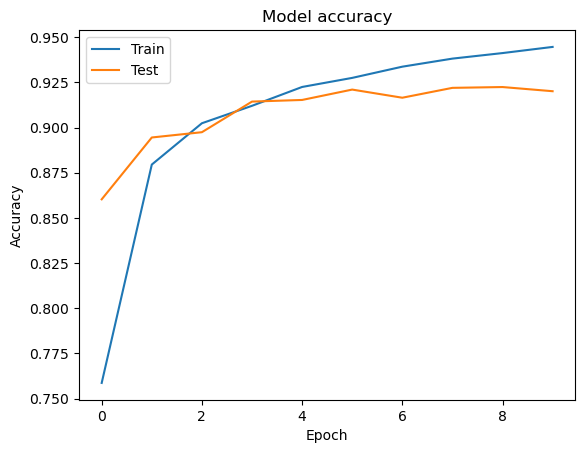

In [17]:
def plot_accuracy(acc,val_acc):
  # Plot training & validation accuracy values
  plt.figure()
  plt.plot(acc)
  plt.plot(val_acc)
  plt.title('Model accuracy')
  plt.ylabel('Accuracy')
  plt.xlabel('Epoch')
  plt.legend(['Train', 'Test'], loc='upper left')
  plt.show()

plot_accuracy(history.history['accuracy'], history.history['val_accuracy'])

MODEL ACCURACY INCREASES UPTO 3 IN BOTH SETS

ACCURACY FLATTENS FOR TEST SET, TRAINING KEEPS IMPROVING. We are overfitting.

In [18]:
# for size in training_sizes:
#   	# Get a fraction of training data (we only care about the training data)
#     X_train_frac, y_train_frac = X_train[:size], y_train[:size]

#     # Reset the model to the initial weights and train it on the new training data fraction
#     model.set_weights(initial_weights)
#     model.fit(X_train_frac, y_train_frac, epochs = 50, callbacks = [early_stop])

#     # Evaluate and store both: the training data fraction and the complete test set results
#     train_accs.append(model.evaluate(X_train, y_train)[1])
#     test_accs.append(model.evaluate(X_test, y_test)[1])
    
# # Plot train vs test accuracies
# plot_results(train_accs, test_accs)

555/555 [==============================] - 1s 2ms/step


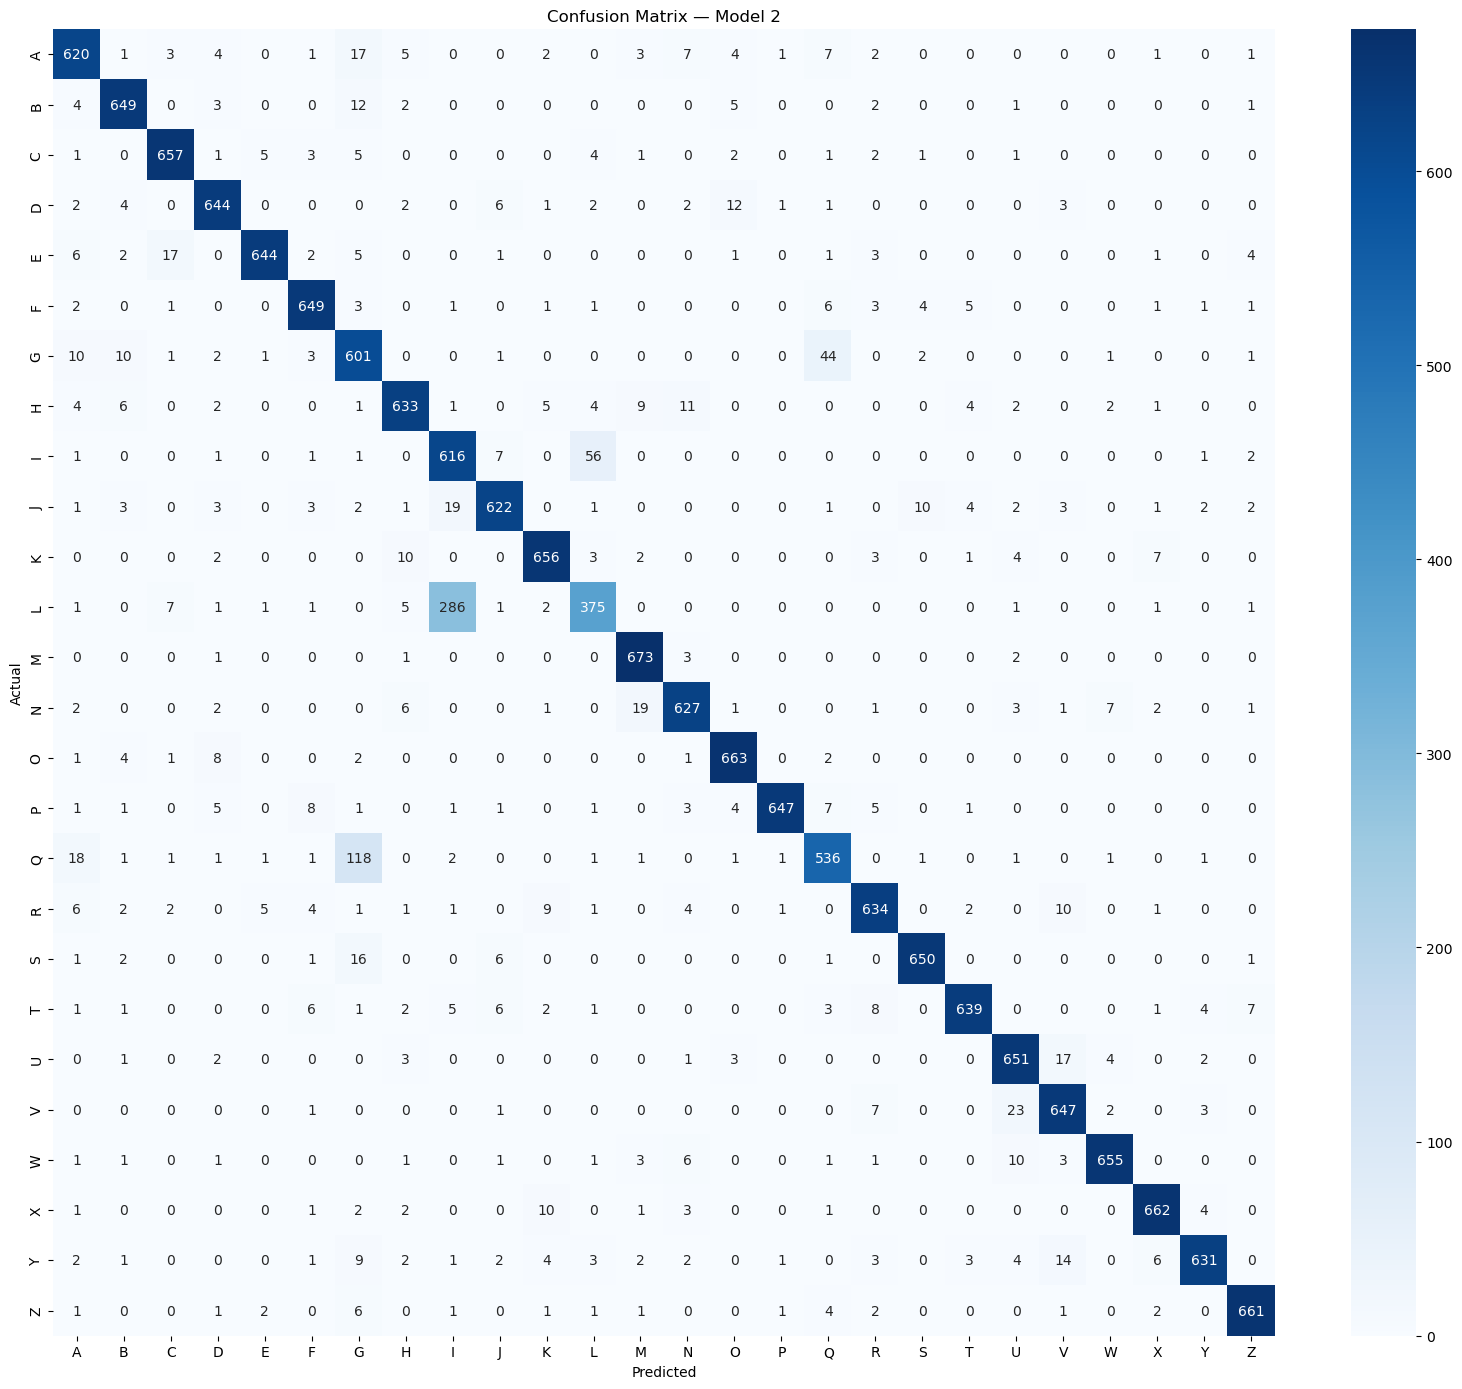

              precision    recall  f1-score   support

           A       0.90      0.91      0.91       679
           B       0.94      0.96      0.95       679
           C       0.95      0.96      0.96       684
           D       0.94      0.95      0.94       680
           E       0.98      0.94      0.96       687
           F       0.95      0.96      0.95       679
           G       0.75      0.89      0.81       677
           H       0.94      0.92      0.93       685
           I       0.66      0.90      0.76       686
           J       0.95      0.91      0.93       680
           K       0.95      0.95      0.95       688
           L       0.82      0.55      0.66       683
           M       0.94      0.99      0.96       680
           N       0.94      0.93      0.93       673
           O       0.95      0.97      0.96       682
           P       0.99      0.94      0.97       686
           Q       0.87      0.78      0.82       687
           R       0.94    

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Map numeric labels back to letters (labels are 1–26)
label_names = [chr(i + 64) for i in range(1, 27)]  # A=1, B=2 ... Z=26

# Confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Model 2')
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(y_true_classes, y_pred_classes, target_names=label_names))

In [20]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 24, 24, 32)        832       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 12, 12, 32)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 12, 12, 32)        0         
                                                                 
 flatten (Flatten)           (None, 4608)              0         
                                                                 
 dense (Dense)               (None, 128)               589952    
                                                                 
 dense_1 (Dense)             (None, 26)                3354      
                                                        

In [21]:


# Build and train the complex model
model2 = Sequential()
model2.add(Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Conv2D(15, (3, 3), activation='relu'))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Dropout(0.2))
model2.add(Flatten())
model2.add(Dense(128, activation='relu'))
model2.add(Dense(50, activation='relu'))
model2.add(Dense(num_classes, activation='softmax'))

model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history2 = model2.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=200, verbose=1)

scores = model2.evaluate(X_test, y_test, verbose=0)
print("CNN Error: %.2f%%" % (100 - scores[1] * 100))

Epoch 1/10
356/356 [==============================] - 4s 10ms/step - loss: 1.1235 - accuracy: 0.6563 - val_loss: 0.4773 - val_accuracy: 0.8468
Epoch 2/10
356/356 [==============================] - 3s 8ms/step - loss: 0.4630 - accuracy: 0.8513 - val_loss: 0.3442 - val_accuracy: 0.8928
Epoch 3/10
356/356 [==============================] - 3s 7ms/step - loss: 0.3633 - accuracy: 0.8798 - val_loss: 0.3011 - val_accuracy: 0.9037
Epoch 4/10
356/356 [==============================] - 3s 8ms/step - loss: 0.3123 - accuracy: 0.8970 - val_loss: 0.2831 - val_accuracy: 0.9090
Epoch 5/10
356/356 [==============================] - 3s 9ms/step - loss: 0.2850 - accuracy: 0.9051 - val_loss: 0.2560 - val_accuracy: 0.9171
Epoch 6/10
356/356 [==============================] - 4s 12ms/step - loss: 0.2608 - accuracy: 0.9122 - val_loss: 0.2356 - val_accuracy: 0.9242
Epoch 7/10
356/356 [==============================] - 3s 10ms/step - loss: 0.2467 - accuracy: 0.9158 - val_loss: 0.2285 - val_accuracy: 0.9277
Epo

In [22]:
model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 24, 24, 30)        780       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 12, 12, 30)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 10, 10, 15)        4065      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 5, 5, 15)         0         
 2D)                                                             
                                                                 
 dropout_1 (Dropout)         (None, 5, 5, 15)          0         
                                                                 
 flatten_1 (Flatten)         (None, 375)              

In [23]:
import matplotlib.pyplot as plt
print(history.history.keys())


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


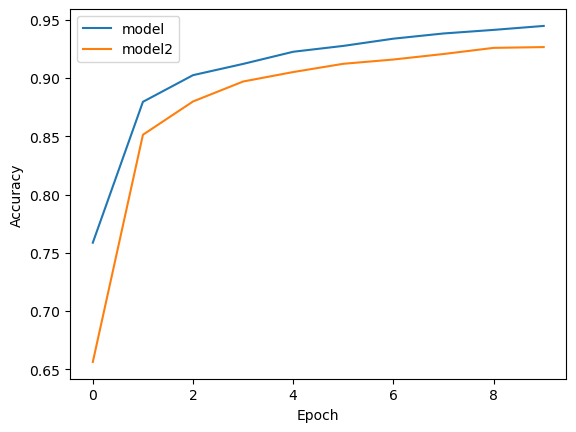

In [24]:
plt.plot(history.history['accuracy'])
plt.plot(history2.history['accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['model', 'model2'], loc='upper left')
plt.show()

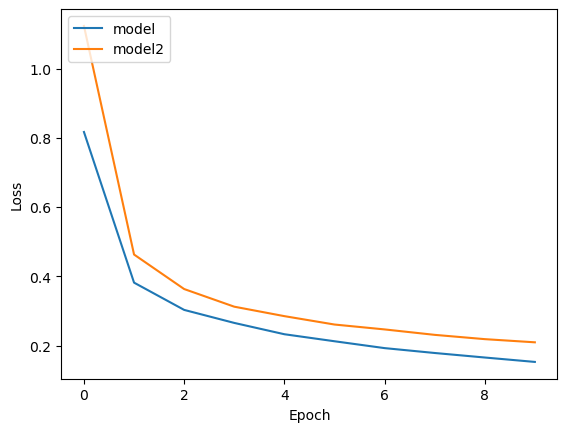

In [25]:
plt.plot(history.history['loss'])
plt.plot(history2.history['loss'])
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['model', 'model2'], loc='upper left')
plt.show()

In [26]:
model.save_weights('CA2PtA.weights.h5')


# ResNet-style CNN

The code below keeps the same CA1 data split, normalisation, one-hot encoding, optimiser, batch size, and training style. The only architecture change is that the CNN now has residual blocks. Each residual block adds its input back to the convolution output, so a deeper network can learn useful refinements without losing the original feature information.


In [27]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Add, BatchNormalization, Activation, GlobalAveragePooling2D

# Residual block: Conv -> BatchNorm -> ReLU -> Conv -> BatchNorm + shortcut
def residual_block(x, filters, stride=1):
    shortcut = x

    x = Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(filters, (3, 3), padding='same', use_bias=False)(x)
    x = BatchNormalization()(x)

    # Change shortcut shape when the block changes the number of filters or image size
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x


In [28]:
# Build and train the ResNet-style model
inputs = Input(shape=(28, 28, 1))

x = Conv2D(32, (3, 3), padding='same', use_bias=False)(inputs)
x = BatchNormalization()(x)
x = Activation('relu')(x)

# 28x28 stage
x = residual_block(x, 32)

# 14x14 stage
x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

# 7x7 stage
x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model3 = Model(inputs, outputs, name='ResNet_style_CNN')
model3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history3 = model3.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=200,
    verbose=1
)

scores = model3.evaluate(X_test, y_test, verbose=0)
print("ResNet CNN Error: %.2f%%" % (100 - scores[1] * 100))


Epoch 1/10
356/356 [==============================] - 35s 87ms/step - loss: 0.5825 - accuracy: 0.8263 - val_loss: 5.3411 - val_accuracy: 0.1255
Epoch 2/10
356/356 [==============================] - 29s 82ms/step - loss: 0.2339 - accuracy: 0.9223 - val_loss: 0.2743 - val_accuracy: 0.9067
Epoch 3/10
356/356 [==============================] - 30s 85ms/step - loss: 0.1943 - accuracy: 0.9341 - val_loss: 0.2069 - val_accuracy: 0.9315
Epoch 4/10
356/356 [==============================] - 32s 89ms/step - loss: 0.1722 - accuracy: 0.9403 - val_loss: 0.2220 - val_accuracy: 0.9298
Epoch 5/10
356/356 [==============================] - 33s 92ms/step - loss: 0.1581 - accuracy: 0.9438 - val_loss: 0.3034 - val_accuracy: 0.9016
Epoch 6/10
356/356 [==============================] - 31s 86ms/step - loss: 0.1496 - accuracy: 0.9466 - val_loss: 0.1633 - val_accuracy: 0.9465
Epoch 7/10
356/356 [==============================] - 30s 86ms/step - loss: 0.1386 - accuracy: 0.9510 - val_loss: 0.1611 - val_accuracy:

In [29]:
model3.summary()


Model: "ResNet_style_CNN"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d_3 (Conv2D)              (None, 28, 28, 32)   288         ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (None, 28, 28, 32)  128         ['conv2d_3[0][0]']               
 alization)                                                                                       
                                                                                                  
 activation (Activation)        (None, 28, 28, 32)   0           ['batch_normalizat

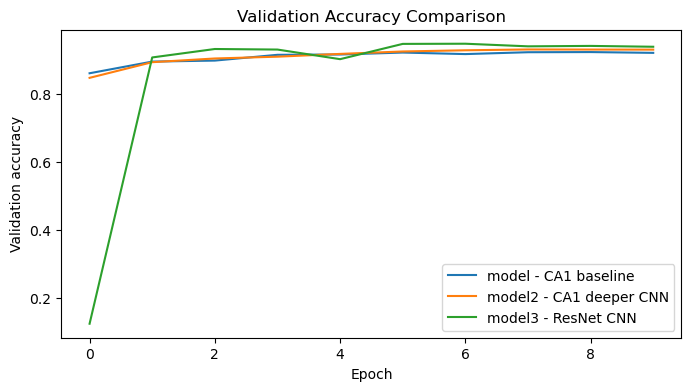

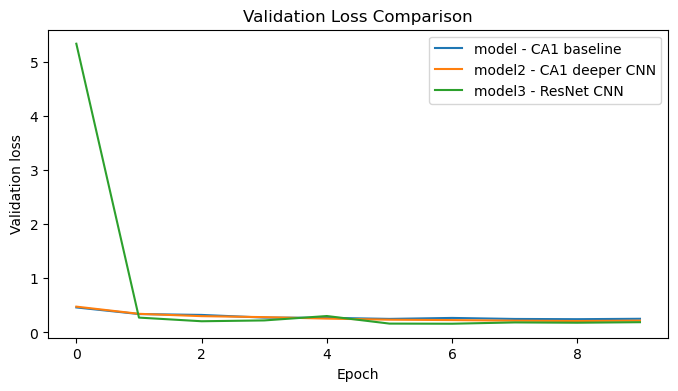

In [30]:
# Compare your original CA1 baseline, your original deeper model, and the ResNet-style CNN
plt.figure(figsize=(8, 4))
plt.plot(history.history['val_accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.plot(history3.history['val_accuracy'])
plt.ylabel('Validation accuracy')
plt.xlabel('Epoch')
plt.legend(['model - CA1 baseline', 'model2 - CA1 deeper CNN', 'model3 - ResNet CNN'], loc='lower right')
plt.title('Validation Accuracy Comparison')
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history['val_loss'])
plt.plot(history2.history['val_loss'])
plt.plot(history3.history['val_loss'])
plt.ylabel('Validation loss')
plt.xlabel('Epoch')
plt.legend(['model - CA1 baseline', 'model2 - CA1 deeper CNN', 'model3 - ResNet CNN'], loc='upper right')
plt.title('Validation Loss Comparison')
plt.show()


555/555 [==============================] - 3s 5ms/step


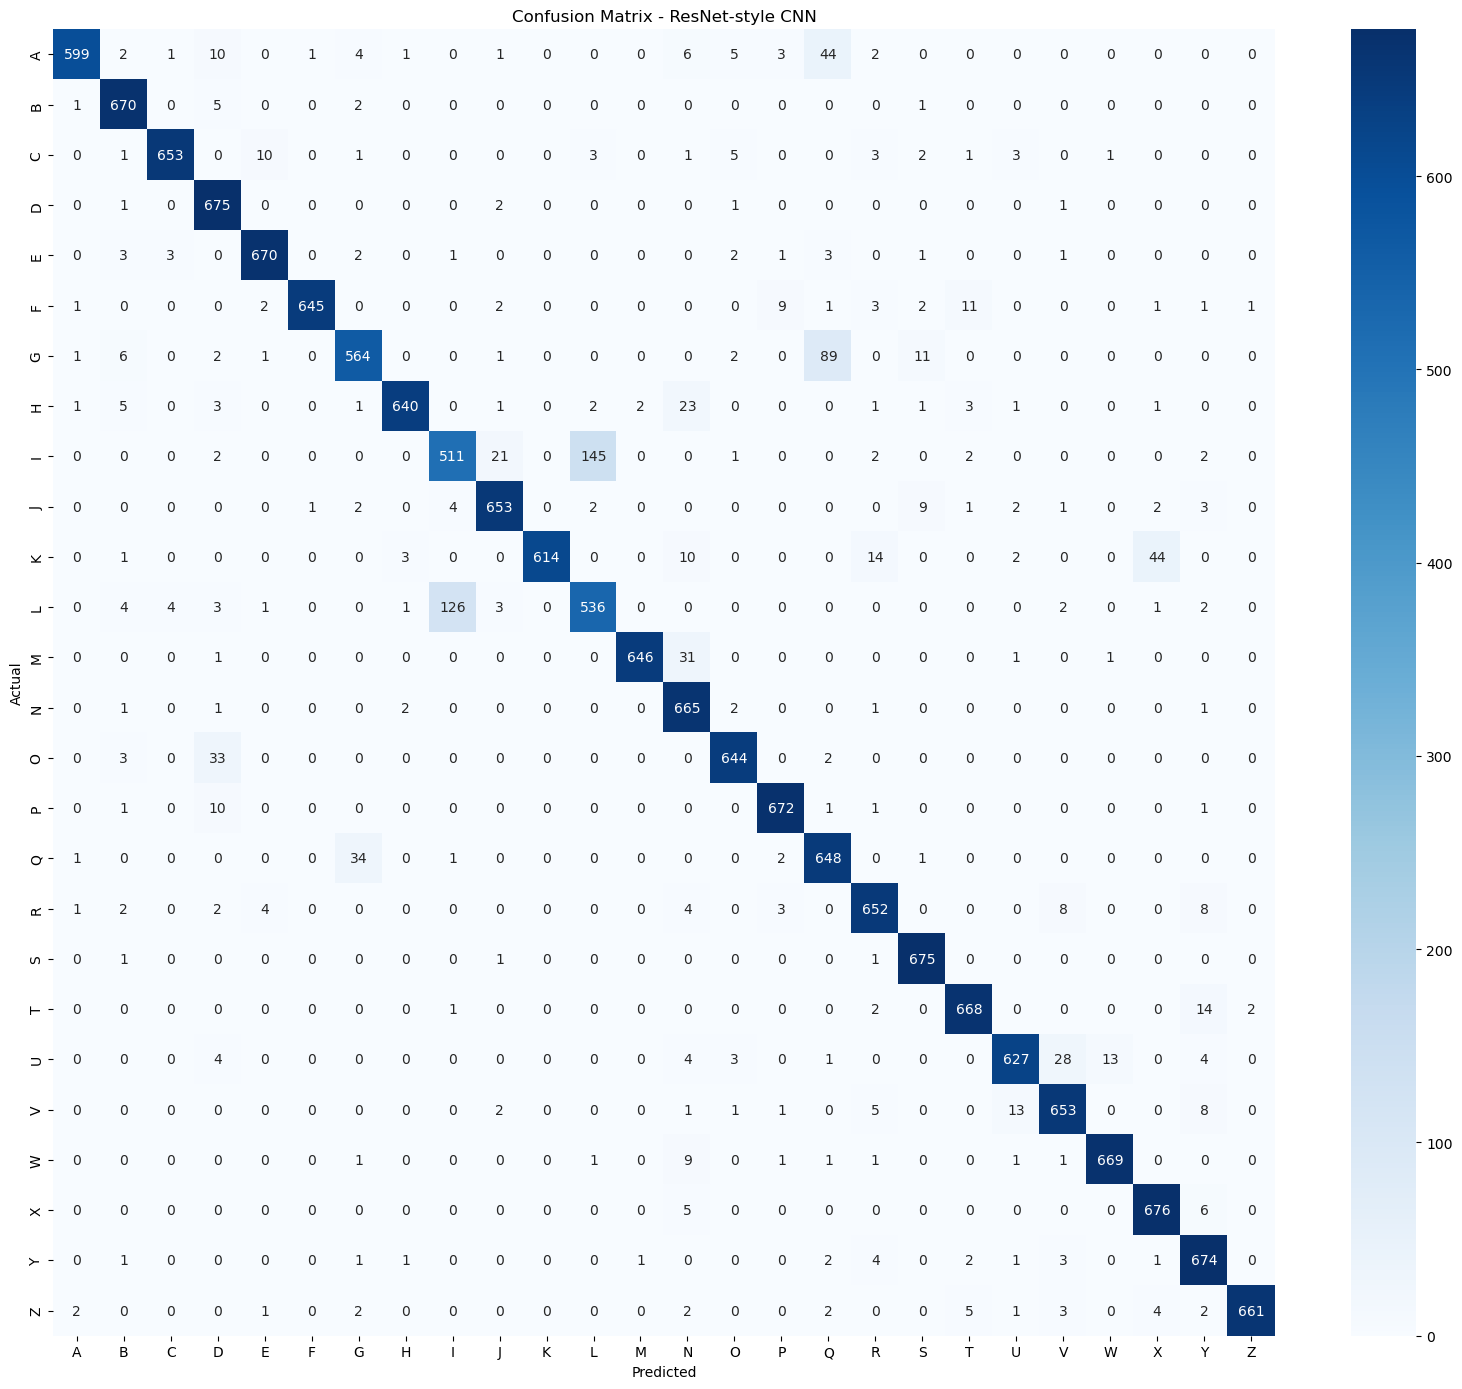

              precision    recall  f1-score   support

           A       0.99      0.88      0.93       679
           B       0.95      0.99      0.97       679
           C       0.99      0.95      0.97       684
           D       0.90      0.99      0.94       680
           E       0.97      0.98      0.97       687
           F       1.00      0.95      0.97       679
           G       0.92      0.83      0.87       677
           H       0.99      0.93      0.96       685
           I       0.79      0.74      0.77       686
           J       0.95      0.96      0.96       680
           K       1.00      0.89      0.94       688
           L       0.78      0.78      0.78       683
           M       1.00      0.95      0.97       680
           N       0.87      0.99      0.93       673
           O       0.97      0.94      0.96       682
           P       0.97      0.98      0.98       686
           Q       0.82      0.94      0.88       687
           R       0.94    

In [31]:
# Confusion matrix and classification report for the ResNet-style model
y_pred = model3.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

label_names = [chr(i + 65) for i in range(26)]  # A=0, B=1 ... Z=25

cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ResNet-style CNN')
plt.tight_layout()
plt.show()

print(classification_report(y_true_classes, y_pred_classes, target_names=label_names))


In [32]:
# Save the best Part C model weights
model3.save_weights('PartC_ResNet_EMNIST_best.weights.h5')
